# Módulo 55: Modelos AR — Solución
Author: Juliho Castillo Colmenares Ph.D.

Enunciado para estudiantes: [m55-modelos-ar-guia.ipynb](m55-modelos-ar-guia.ipynb) · Lección: [m55-modelos-ar-leccion.ipynb](m55-modelos-ar-leccion.ipynb)

## Contexto

Un analista sigue la acción de **The Walt Disney Company** (`DIS`) y quiere un modelo autorregresivo AR($p$) para anticipar su precio de cierre a corto plazo: ajustarlo con los datos del primer trimestre de 2023, medir qué tan bien habría pronosticado las últimas semanas del trimestre y proyectar el precio a partir de abril con un intervalo del 90 %.

## Datos

Precios diarios de `DIS` del 2023-01-01 al 2023-03-30 (61 sesiones), descargados de Yahoo Finance con `yfinance` (requiere internet); se usa el cierre ajustado `Close`.

## Instrucciones

1. **Autocorrelación parcial:** PACF con 20 rezagos.
2. **Elegir $p$ con AIC y BIC** para $p = 1, \dots, 10$.
3. **Dividir los datos y ajustar el modelo:** 70 % entrenamiento y 30 % prueba, en orden temporal.
4. **Pronosticar con intervalos al 90 %:** periodo de prueba y 30 días hábiles desde abril de 2023, con los intervalos del modelo.
5. **Evaluar el modelo y revisar el orden:** MSE y MAPE de prueba; BIC con muestra común (`hold_back`) y justificación del orden.
6. **Graficar los resultados:** histórico, predicciones de prueba, pronóstico e intervalo.

*El enunciado original del curso no se conserva; estas instrucciones se reconstruyeron a partir de la solución.*


### Descarga de los datos

In [1]:
# Import necessary libraries
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
from statsmodels.tsa.ar_model import AutoReg
from statsmodels.graphics.tsaplots import plot_pacf
from sklearn.metrics import mean_squared_error, mean_absolute_percentage_error

In [2]:
# Suppress warnings
warnings.filterwarnings("ignore")

In [3]:
# Step 1: Download historical data for Walt Disney (DIS) from Yahoo Finance
start_date = "2023-01-01"
end_date = "2023-03-31"
data = yf.download("DIS", start=start_date, end=end_date)
close_prices = data["Close"]

[*********************100%***********************]  1 of 1 completed

### Tarea 1. Autocorrelación parcial

<Figure size 1000x500 with 0 Axes>

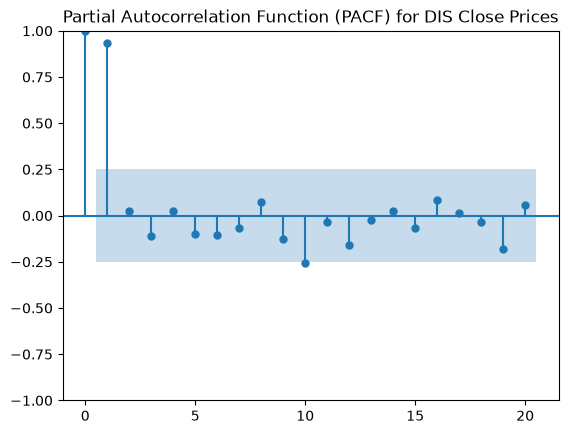

In [4]:
# Step 2: Plot Partial Autocorrelation Function (PACF) to determine the order of AR model (p)
plt.figure(figsize=(10, 5))
plot_pacf(close_prices, lags=20, method="ywm")
plt.title("Partial Autocorrelation Function (PACF) for DIS Close Prices")
plt.show()

### Tarea 2. Elegir $p$ con AIC y BIC

In [5]:
# Step 3: Fit AR models with different lags and calculate AIC and BIC
aic_values = []
bic_values = []
max_lag = 10  # Testing up to AR(10)

for lag in range(1, max_lag + 1):
    model = AutoReg(close_prices, lags=lag).fit()
    aic_values.append(model.aic)
    bic_values.append(model.bic)

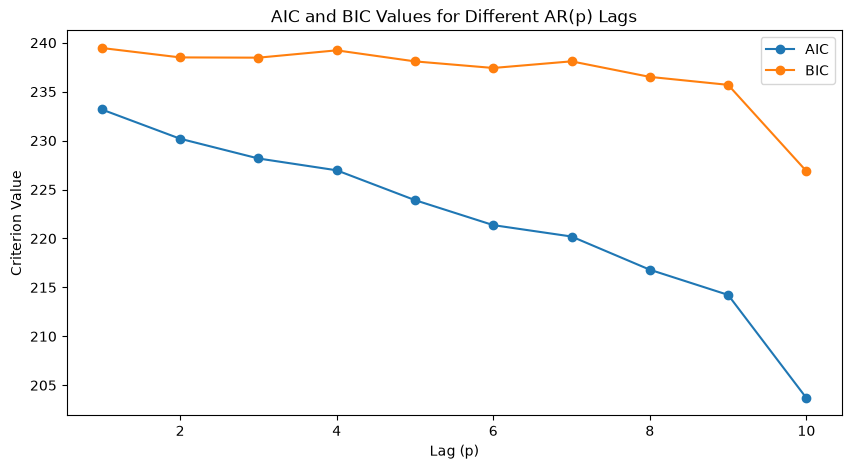

In [6]:
# Plot AIC and BIC for each lag
plt.figure(figsize=(10, 5))
plt.plot(range(1, max_lag + 1), aic_values, marker="o", label="AIC")
plt.plot(range(1, max_lag + 1), bic_values, marker="o", label="BIC")
plt.xlabel("Lag (p)")
plt.ylabel("Criterion Value")
plt.title("AIC and BIC Values for Different AR(p) Lags")
plt.legend()
plt.show()

In [7]:
# Step 4: Select the optimal lag based on minimum AIC/BIC values
optimal_lag = np.argmin(aic_values) + 1
optimal_lag_bic = np.argmin(bic_values) + 1
print(f"Optimal lag (p) selected based on AIC: {optimal_lag}")
print(f"Optimal lag (p) selected based on BIC: {optimal_lag_bic}")

Optimal lag (p) selected based on AIC: 10
Optimal lag (p) selected based on BIC: 10


### Tarea 3. Dividir los datos y ajustar el modelo

In [8]:
# Step 5: Train-Test Split (70% train, 30% test)
train_size = int(len(close_prices) * 0.7)
train_data = close_prices[:train_size]
test_data = close_prices[train_size:]

In [9]:
# Step 6: Fit the AR model with the optimal lag on the training set
model = AutoReg(train_data, lags=optimal_lag).fit()

### Tarea 4. Pronosticar con intervalos al 90 %

In [10]:
# Step 7: Forecast for the testing period and for April 2023 (30 days ahead)
test_predictions = model.predict(
    start=len(train_data), end=len(close_prices) - 1, dynamic=False
)
forecast = model.predict(
    start=len(close_prices), end=len(close_prices) + 29, dynamic=False
)

In [11]:
# Calculate 90% intervals for the forecast from the model itself. Their width grows with the
# horizon, because multi-step errors accumulate; a constant band of 1.645 * sd(residuals)
# would understate the uncertainty. get_prediction must start at the end of the training
# sample, so we keep only the last 30 rows (April).
prediction_frame = model.get_prediction(
    start=len(train_data), end=len(close_prices) + 29
).summary_frame(alpha=0.1)
confidence_interval_lower = prediction_frame["mean_ci_lower"].iloc[-30:]
confidence_interval_upper = prediction_frame["mean_ci_upper"].iloc[-30:]
half_width = (confidence_interval_upper - confidence_interval_lower) / 2
print(f"90% interval half-width: {half_width.iloc[0]:.2f} (first April day), {half_width.iloc[-1]:.2f} (last)")

90% interval half-width: 4.72 (first April day), 5.24 (last)


### Tarea 5. Evaluar el modelo y revisar el orden

In [12]:
# Step 8: Evaluate model accuracy on the test set
mse = mean_squared_error(test_data, test_predictions)
mape = mean_absolute_percentage_error(test_data, test_predictions)
print(f"Test Set MSE: {mse}")
print(f"Test Set MAPE: {mape}")

Test Set MSE: 65.54970256500374
Test Set MAPE: 0.08101243106864217


In [13]:
# Order check: p=10 is at the edge of the grid 1..10. In the loop above each AutoReg drops
# its first p observations, so AIC/BIC are computed on different samples. With a common
# sample for every lag (hold_back=max_lag) the BIC selects:
bic_common = [
    AutoReg(close_prices, lags=lag, hold_back=max_lag).fit().bic
    for lag in range(1, max_lag + 1)
]
lag_common = np.argmin(bic_common) + 1
alt_model = AutoReg(train_data, lags=lag_common).fit()
alt_predictions = alt_model.predict(start=len(train_data), end=len(close_prices) - 1)
print(f"BIC on a common sample selects p={lag_common}")
print(f"Test Set MSE with p={lag_common}: {mean_squared_error(test_data, alt_predictions)}")
print(f"Test Set MSE with p={optimal_lag}: {mse}")

BIC on a common sample selects p=1
Test Set MSE with p=1: 76.60454291764862
Test Set MSE with p=10: 65.54970256500374


**Order used.** Both AIC and BIC choose p = 10, the upper edge of the grid, with only 61 observations. In the grid each AutoReg drops its first p observations, so the criteria are not computed on the same sample; on a common sample the BIC selects p = 1. We keep p = 10 because it gives the lower test-set MSE (65.5 against 76.6 for p = 1), but with so few observations this order should be read with caution, since it may be fitting noise.

### Tarea 6. Graficar los resultados

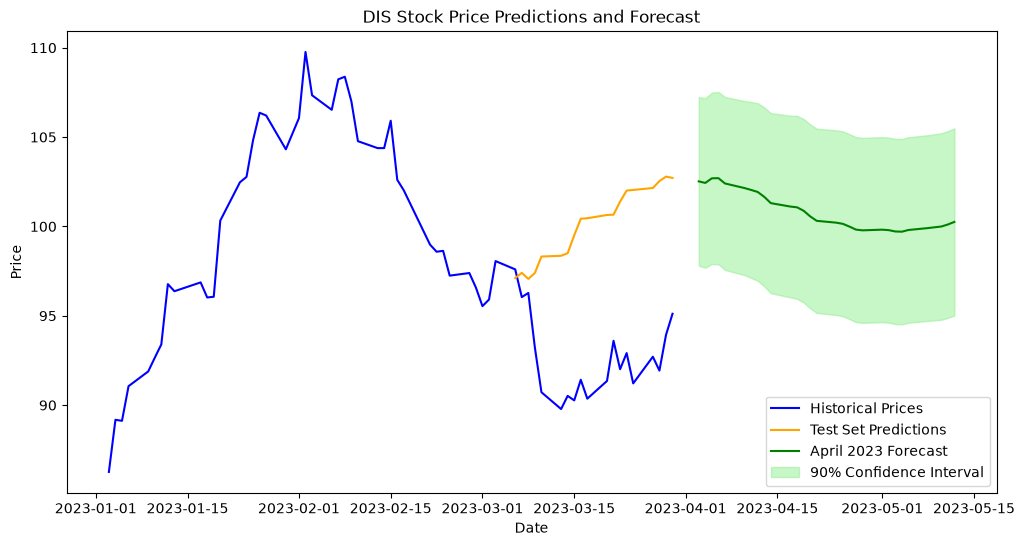

In [14]:
# Step 9: Plot the results
forecast_index = pd.date_range(start="2023-04-01", periods=30, freq="B")
plt.figure(figsize=(12, 6))
plt.plot(close_prices.index, close_prices, label="Historical Prices", color="blue")
plt.plot(
    test_data.index, test_predictions, label="Test Set Predictions", color="orange"
)
plt.plot(forecast_index, forecast, label="April 2023 Forecast", color="green")
plt.fill_between(
    forecast_index,
    confidence_interval_lower[:30],
    confidence_interval_upper[:30],
    color="lightgreen",
    alpha=0.5,
    label="90% Confidence Interval",
)
plt.legend()
plt.title("DIS Stock Price Predictions and Forecast")
plt.xlabel("Date")
plt.ylabel("Price")
plt.show()

**Revisión posterior (2026-10):** la banda al 90 % de ancho constante (pronóstico ± 1.645·sd de los residuos), que además salía vacía porque restar una Serie a un DataFrame producía solo NaN, se sustituyó por los intervalos del modelo (`get_prediction(...).summary_frame(alpha=0.1)`), que crecen con el horizonte; también se reporta el p que elige el BIC y se justifica el orden usado. Al re-ejecutar, yfinance devuelve precios ajustados, por lo que el MSE de prueba pasa de 69.73 a 65.55 (el MAPE se mantiene en 0.081). El PDF conserva la versión entregada.